# 数墙：把格子点连成一条闭合回路

## 这一章讲什么

[数墙](https://ja.puzzle-loop.com/)是一个画出一条闭合回路的谜题。由于回路本身就是把格子点连成一个圈，因此 `add_circuit()` 拿来就能用，整个问题基本可以按回路问题处理。

- 盘面的格子点当顶点、线段当边，先搭出一个图
- 回路不经过的点，用自环 `(i, i)` 交代
- 每个方格四周画了几条线，用 `sum(...) == 数字` 卡住

## 规则

1. 画线
   - 沿横向和纵向把格子点连起来，一条接一条地画。线不能中断，也不能交叉、分叉。
2. 数字的含义
   - 方格里的数字表示这个方格四周画了几条线。写 0 就一条也不能画；不写数字的方格不加限制。
3. 形成闭合回路
   - 所有的线连成一个整体，收口闭合。

`````{admonition} 数墙谜题的网站
:class: tip
https://ja.puzzle-loop.com

用 `helper.puzzle.extract_slither_link()` 能把这个网站的谜题盘面取下来。打开浏览器的开发者工具，复制表示盘面的 `<div>` 标签代码，再执行这个函数，盘面就变成数组了。
`````

![](https://www.nikoli.co.jp/en/wp-content/themes/nikoli_en/images/puzzles/slitherlink03.gif)

## 思路

- 顶点取盘面的格子点，也就是方格的角，$h \times w$ 的盘面一共有 $(h+1) \times (w+1)$ 个格子点
- 相邻两个格子点之间连一条边，两个方向都得备着，去程和回程各算一条
- 回路未必路过所有格子点，因此每个点都加一条自环 `(i, i)`
- 一个方格四周的 4 条线里，被选中的条数要跟数字对得上

由于 `add_circuit()` 出来的一定是“一条回路”，因此不可能出现两个互不相连的圈。

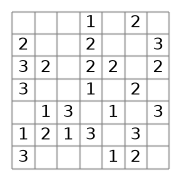

In [1]:
from ortools.sat.python import cp_model
import numpy as np
from matplotlib import pyplot as plt
from matplotlib.collections import LineCollection
from collections import defaultdict


def plot_slither_link_board(board, result=None):
    """画出盘面和求解出的回路"""
    h, w = board.shape

    fig, ax = plt.subplots(figsize=(w * 0.3, h * 0.3))
    ax.set_ylim(-0.1, h + 0.1)
    ax.set_xlim(-0.1, w + 0.1)
    ax.invert_yaxis()
    ax.set_aspect("equal")

    all_segments = []      # 所有可以画的线（浅灰色）
    circuit_segments = []  # 被选中的线（绿色）

    if result is not None:
        for (n1, n2), flag in result.items():
            if flag:
                r1, c1 = n1 // (w + 1), n1 % (w + 1)
                r2, c2 = n2 // (w + 1), n2 % (w + 1)
                circuit_segments.append([(c1, r1), (c2, r2)])

    for r, c in np.ndindex(h + 1, w + 1):
        if r + 1 <= h:
            all_segments.append([(c, r), (c, r + 1)])
        if c + 1 <= w:
            all_segments.append([(c, r), (c + 1, r)])

    ax.add_collection(LineCollection(all_segments, color='gray', alpha=0.5))
    ax.add_collection(LineCollection(circuit_segments, color='green', linewidth=2))
    for (i, j), v in np.ndenumerate(board):
        if v != -1:
            ax.text(j + 0.5, i + 0.5, str(v), fontsize=12, va='center', ha='center')
    ax.autoscale_view()
    ax.axis('off')
    return fig, ax


board = np.loadtxt('data/slitherlink01.txt', dtype=np.int8)
plot_slither_link_board(board);

`-1` 表示这个方格没有数字，也就是对这一格不加任何限制。

## 求解

`SlitherLinkSolver` 从盘面出发建模型，再交给求解器去算，两件事一次做完。

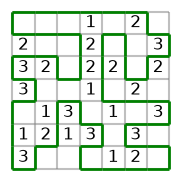

In [2]:
class SlitherLinkSolver:
    def __init__(self, board):
        self.board = board
        h, w = self.board.shape

        # 给格子点从 0 开始连续编号
        self.nodes = nodes = np.arange((h + 1) * (w + 1)).reshape(h + 1, w + 1)

        # 连接相邻格子点的有向边（两个方向）
        self.edges = edges = []
        for (r, c), s in np.ndenumerate(nodes):
            if c + 1 <= w:
                e = nodes[r, c + 1]
                edges.extend([(s, e), (e, s)])
            if r + 1 <= h:
                e = nodes[r + 1, c]
                edges.extend([(s, e), (e, s)])

        # 收集每个方格四周的 4 条线（两个方向共 8 条）
        self.cell_edges = cell_edges = defaultdict(set)
        for (r, c), _ in np.ndenumerate(board):
            n1 = nodes[r, c]
            n2 = nodes[r, c + 1]
            n3 = nodes[r + 1, c]
            n4 = nodes[r + 1, c + 1]
            for edge in [(n1, n2), (n1, n3), (n2, n4), (n3, n4)]:
                cell_edges[r, c].add(edge)
                cell_edges[r, c].add(edge[::-1])

        model = cp_model.CpModel()
        variables = {e: model.new_bool_var(f'edge{e}') for e in edges}

        # 表示不经过的格子点的自环
        dummies = [(i, i, model.new_bool_var(f'dummy_{i}'))
                   for i in range((h + 1) * (w + 1))]
        model.add_circuit([(s, e, v) for (s, e), v in variables.items()] + dummies)

        # 方格四周的线数
        for (r, c), count in np.ndenumerate(board):
            if count != -1:
                box_edges = [variables[edge] for edge in cell_edges[r, c]]
                model.add(sum(box_edges) == int(count))

        solver = cp_model.CpSolver()
        if solver.solve(model) not in (cp_model.OPTIMAL, cp_model.FEASIBLE):
            raise ValueError("没有找到解")
        self.result = {key: solver.value(val) for key, val in variables.items()}


solver = SlitherLinkSolver(board)
plot_slither_link_board(board, solver.result);

## 代码说明

第 1 步，给格子点编号

$h \times w$ 的盘面有 $(h+1) \times (w+1)$ 个格子点。二维数组处理起来不方便，因此先用 `np.arange()` 从 0 开始连续编号，压成一维的 ID。

第 2 步，建立边

每个格子点朝“右”和“下”各连一条，再把两个方向都加进去，由于 `add_circuit()` 管的是有向边，因此去程和回程这两条边少一条都不行。

第 3 步，收集方格四周的线

从方格 `(r, c)` 四个角的格子点取出上、左、右、下 4 条线，两个方向都放进去就有 8 条。这样在后面数“选中了几条”时就不必再管方向：一条线只会被选走一个方向，加起来就是条数。

第 4 步，用自环表示“不经过的点”

回路用不到所有的格子点，加上 `(i, i, var)` 之后，这个点就可以选择不用，直接排除在回路之外。

第 5 步，数字的约束

```python
model.add(sum(box_edges) == int(count))
```

让方格四周的线数与数字一致，这一条就是数墙的全部约束。

## 更难的谜题

谜题网站上最难的那一档盘面，也拿来试一次，看同样的写法能不能直接解出来。

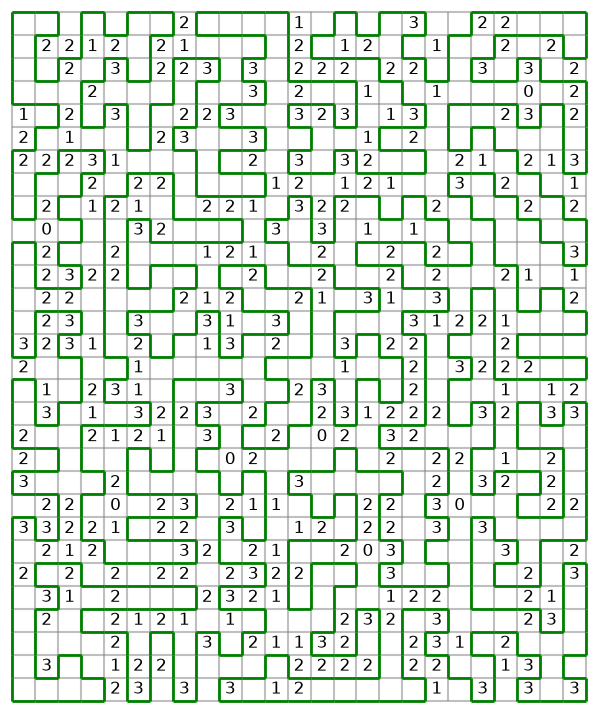

In [3]:
board = np.loadtxt('data/slitherlink02.txt', dtype=np.int8)
solver = SlitherLinkSolver(board)
plot_slither_link_board(board, solver.result);

## 验算

把解出来的回路对照规则，一条一条核过去。

In [4]:
def check_slither(board, result):
    """确认每个方格的线数，以及回路是否只有一条"""
    h, w = board.shape
    lines = set()
    for (n1, n2), flag in result.items():
        if flag:
            lines.add(tuple(sorted((n1, n2))))

    # 1. 每个方格四周的线数
    for (r, c), count in np.ndenumerate(board):
        if count == -1:
            continue
        n1 = r * (w + 1) + c
        n2, n3, n4 = n1 + 1, n1 + w + 1, n1 + w + 2
        box = [tuple(sorted(e)) for e in [(n1, n2), (n1, n3), (n2, n4), (n3, n4)]]
        if sum(1 for e in box if e in lines) != count:
            return False, f"方格 {(r, c)} 的线数不对"

    # 2. 回路是否只有一条（沿度为 2 的点能否走一圈）
    adj = defaultdict(list)
    for a, b in lines:
        adj[a].append(b)
        adj[b].append(a)
    for node, nb in adj.items():
        if len(nb) != 2:
            return False, f"格子点 {node} 的度不是 2"

    start = next(iter(adj))
    prev, cur, count = None, start, 0
    while True:
        count += 1
        nxt = adj[cur][0] if adj[cur][0] != prev else adj[cur][1]
        prev, cur = cur, nxt
        if cur == start:
            break
    if count != len(adj):
        return False, "回路不是一条"
    return True, f"{count} 个点组成的一条回路"


print(check_slither(solver.board, solver.result))

(True, '782 个点组成的一条回路')


## 小结

- 格子点当顶点、线段当边，数墙就变成了“找一条回路”的问题
- 回路不经过的点，用自环 `(i, i)` 表示
- 方格四周的线，两个方向一共 8 条，求和就知道选中了几条
- `add_circuit()` 保证出来的是一条回路，因此不会分裂成两个圈
- 解出来之后还得运行一次验算的代码，把规则重新核一次